# Experiment 7: Perceptron and Forward Propagation

A bank screens small loan applications from credit score and income-to-debt ratio. A single perceptron can learn a linear approval boundary, but it cannot represent XOR. We implement the learning rule and compare activations.

**Tools:** NumPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Implement weighted sum, bias and step activation.  2. Train on 100 synthetic loan records and record epoch updates.  3. Plot the learned boundary.  4. Train on XOR and show non-convergence.  5. Compare step, sigmoid and ReLU outputs.

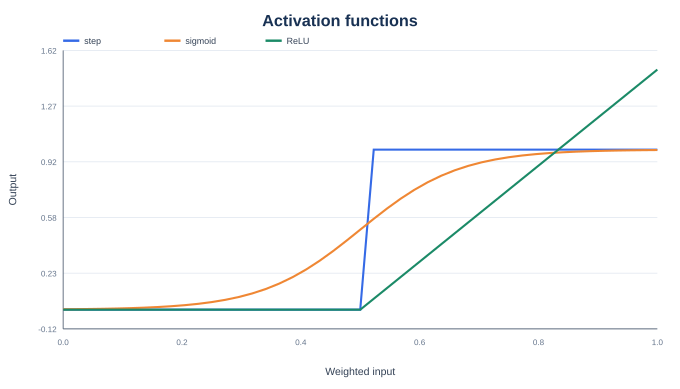

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
X = rng.normal(size=(100, 2))
y = ((1.4*X[:,0] - 1.1*X[:,1] + .15) > 0).astype(int)
w = np.zeros(2); b = 0.0; lr = .08; updates = []
for epoch in range(25):
    errors = 0
    for xi, target in zip(X, y):
        pred = int(w @ xi + b >= 0)
        delta = target - pred
        if delta:
            w += lr * delta * xi; b += lr * delta; errors += 1
    updates.append(errors)
    if errors == 0: break
print("Learned weights:", np.round(w, 3), "bias:", round(b, 3))
print("Training accuracy:", np.mean((X @ w + b >= 0) == y))
plt.figure(figsize=(6, 4))
plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", edgecolor="k", s=28)
xx = np.linspace(X[:,0].min(), X[:,0].max(), 150)
if abs(w[1]) > 1e-9: plt.plot(xx, -(w[0]*xx+b)/w[1], "k--", label="perceptron boundary")
plt.xlabel("Credit score (standardised)"); plt.ylabel("Debt ratio (standardised)")
plt.title("Loan approval perceptron"); plt.legend(); plt.tight_layout(); plt.show()
plt.plot(range(1, len(updates)+1), updates, "o-")
plt.xlabel("Epoch"); plt.ylabel("Weight updates"); plt.title("Perceptron learning rule"); plt.grid(alpha=.2); plt.show()

X_xor = np.array([[0,0],[0,1],[1,0],[1,1]], float)
y_xor = np.array([0,1,1,0])
wx = np.zeros(2); bx = 0.; xor_errors = []
for _ in range(30):
    errors = 0
    for xi, target in zip(X_xor, y_xor):
        delta = target - int(wx @ xi + bx >= 0)
        wx += .1*delta*xi; bx += .1*delta; errors += int(delta != 0)
    xor_errors.append(errors)
print("XOR final mistakes per epoch:", xor_errors[-5:], "(a linear boundary cannot solve XOR)")

z = np.linspace(-2, 2, 200)
sigmoid = 1/(1+np.exp(-z))
plt.figure(figsize=(6, 4))
plt.step(z, (z>=0).astype(float), where="mid", label="step")
plt.plot(z, sigmoid, label="sigmoid")
plt.plot(z, np.maximum(0,z), label="ReLU")
plt.xlabel("Weighted input"); plt.title("Activation functions"); plt.legend(); plt.grid(alpha=.2); plt.show()